# Autoencoder for Dimensionality Reduction and Feature Learning
Nitheeswaran M 24BAD079 

## AIM
To implement and train a simple Autoencoder for dimensionality reduction and feature learning by compressing input data into a lower-dimensional representation and reconstructing the original data from the learned features.


## PART A: Dataset Preparation

Training shape: (60000, 28, 28) dtype: uint8
Testing shape: (10000, 28, 28) dtype: uint8
Original pixel range: 0 to 255
Normalized training data: (60000, 784)
Normalized testing data: (10000, 784)
Normalized pixel range: 0.0 to 1.0
Autoencoder targets are identical to the inputs.


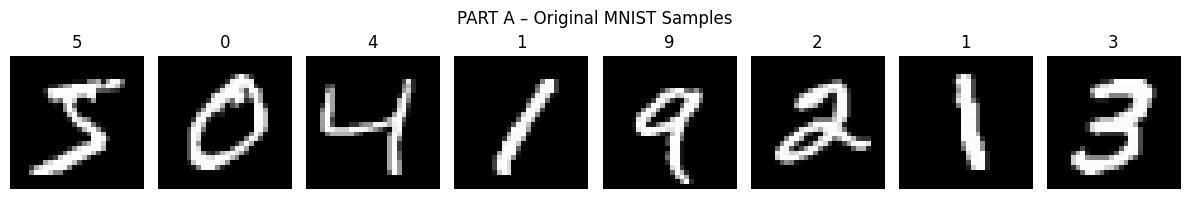

Nitheeswaran M 24BAD079


In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, Model
from sklearn.decomposition import PCA

np.random.seed(42)
tf.random.set_seed(42)

(x_train_img, y_train), (x_test_img, y_test) = tf.keras.datasets.mnist.load_data()
print("Training shape:", x_train_img.shape, "dtype:", x_train_img.dtype)
print("Testing shape:", x_test_img.shape, "dtype:", x_test_img.dtype)
print("Original pixel range:", x_train_img.min(), "to", x_train_img.max())

x_train = x_train_img.astype("float32").reshape(-1, 784) / 255.0
x_test = x_test_img.astype("float32").reshape(-1, 784) / 255.0
print("Normalized training data:", x_train.shape)
print("Normalized testing data:", x_test.shape)
print("Normalized pixel range:", x_train.min(), "to", x_train.max())
print("Autoencoder targets are identical to the inputs.")

fig, axes = plt.subplots(1, 8, figsize=(12, 2))
for i, ax in enumerate(axes):
    ax.imshow(x_train[i].reshape(28, 28), cmap="gray")
    ax.set_title(str(y_train[i]))
    ax.axis("off")
plt.suptitle("PART A – Original MNIST Samples")
plt.tight_layout()
plt.show()
print("Nitheeswaran M 24BAD079")

## PART B: Implementing the Autoencoder

In [6]:
input_layer = layers.Input(shape=(784,), name="image_input")
h = layers.Dense(128, activation="relu", name="encoder_dense_1")(input_layer)
h = layers.Dense(64, activation="relu", name="encoder_dense_2")(h)
latent = layers.Dense(32, activation="relu", name="bottleneck")(h)
encoder = Model(input_layer, latent, name="encoder")

latent_input = layers.Input(shape=(32,), name="latent_input")
d = layers.Dense(64, activation="relu", name="decoder_dense_1")(latent_input)
d = layers.Dense(128, activation="relu", name="decoder_dense_2")(d)
reconstruction = layers.Dense(784, activation="sigmoid", name="reconstructed_image")(d)
decoder = Model(latent_input, reconstruction, name="decoder")

autoencoder = Model(input_layer, decoder(encoder(input_layer)), name="mnist_autoencoder")
autoencoder.compile(optimizer="adam", loss="mse")

print("Encoder summary:")
encoder.summary()
print("Decoder summary:")
decoder.summary()
print("Complete Autoencoder summary:")
autoencoder.summary()
print("Model structure: 784 -> 128 -> 64 -> 32 -> 64 -> 128 -> 784")
print("Nitheeswaran M 24BAD079")

Encoder summary:


Model: "encoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image_input (InputLayer)        │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder_dense_1 (Dense)         │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder_dense_2 (Dense)         │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bottleneck (Dense)              │ (None, 32)             │         2,080 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 110,816 (432.88 KB)

 Trainable params: 110,816 (432.88 KB)

 Non-trainable params: 0 (0.00 B)

... (9 outputs left out)

 Total params: 222,384 (868.69 KB)

 Trainable params: 222,384 (868.69 KB)

 Non-trainable params: 0 (0.00 B)

Model structure: 784 -> 128 -> 64 -> 32 -> 64 -> 128 -> 784
Nitheeswaran M 24BAD079


## PART C: Model Training and Performance Evaluation

Epoch 1/10
211/211 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - loss: 0.0672 - val_loss: 0.0383
Epoch 2/10
211/211 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0323 - val_loss: 0.0276
Epoch 3/10
211/211 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0249 - val_loss: 0.0223
Epoch 4/10
211/211 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0213 - val_loss: 0.0198
Epoch 5/10
211/211 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0193 - val_loss: 0.0182
Epoch 6/10
211/211 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0177 - val_loss: 0.0168
Epoch 7/10
211/211 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0164 - val_loss: 0.0157
Epoch 8/10
211/211 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0154 - val_loss: 0.0148
Epoch 9/10
211/211 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0146 - val_loss: 0.0142
Epoch 10/10
211/211 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0140 - val_loss: 0.0136
Final training loss (MSE): 0.014008
Final validation loss (MSE): 0.013647
Test reconstruction MSE (Keras): 0.013333
Test reconstruction MS

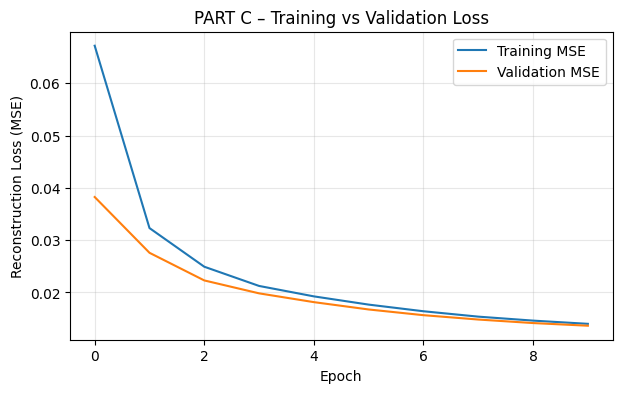

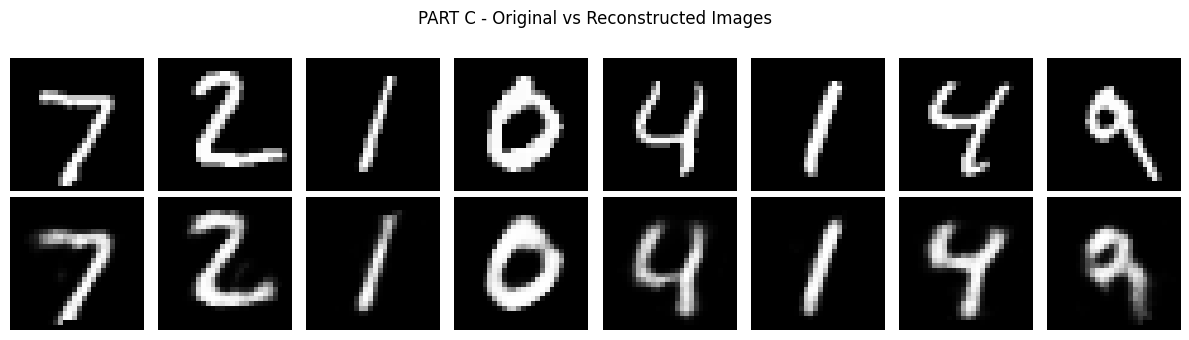

Nitheeswaran M 24BAD079


In [7]:
history = autoencoder.fit(
    x_train, x_train,
    epochs=10,
    batch_size=256,
    validation_split=0.1,
    shuffle=True,
    verbose=1
)

test_mse = autoencoder.evaluate(x_test, x_test, verbose=0)
x_reconstructed = autoencoder.predict(x_test, batch_size=256, verbose=0)
manual_mse = np.mean((x_test - x_reconstructed) ** 2)
print(f"Final training loss (MSE): {history.history['loss'][-1]:.6f}")
print(f"Final validation loss (MSE): {history.history['val_loss'][-1]:.6f}")
print(f"Test reconstruction MSE (Keras): {test_mse:.6f}")
print(f"Test reconstruction MSE (NumPy): {manual_mse:.6f}")

plt.figure(figsize=(7, 4))
plt.plot(history.history["loss"], label="Training MSE")
plt.plot(history.history["val_loss"], label="Validation MSE")
plt.xlabel("Epoch")
plt.ylabel("Reconstruction Loss (MSE)")
plt.title("PART C – Training vs Validation Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

fig, axes = plt.subplots(2, 8, figsize=(12, 3.5))
for i in range(8):
    axes[0, i].imshow(x_test[i].reshape(28, 28), cmap="gray")
    axes[1, i].imshow(x_reconstructed[i].reshape(28, 28), cmap="gray")
    axes[0, i].axis("off")
    axes[1, i].axis("off")
axes[0, 0].set_ylabel("Original", rotation=90)
axes[1, 0].set_ylabel("Reconstructed", rotation=90)
plt.suptitle("PART C - Original vs Reconstructed Images")
plt.tight_layout()
plt.show()
print("Nitheeswaran M 24BAD079")

## PART D: Dimensionality Reduction, Feature Visualization and Experiment Management

Original test shape: (10000, 784)
Learned latent shape: (10000, 32)
Features per image: 784 -> 32
Dimensionality reduction: 95.92%


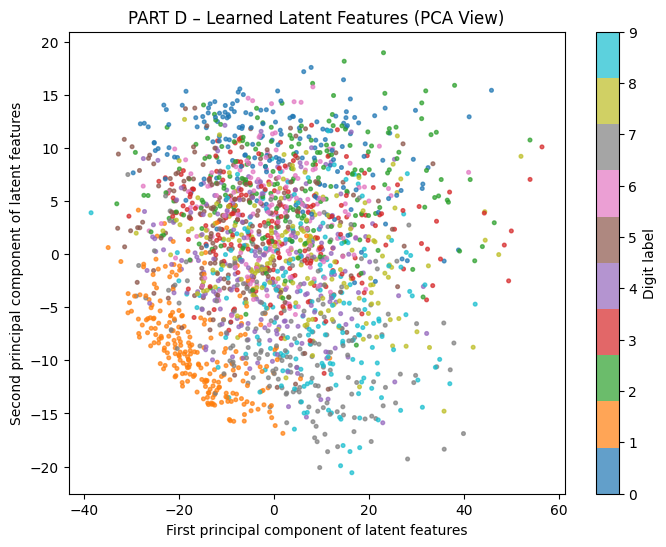

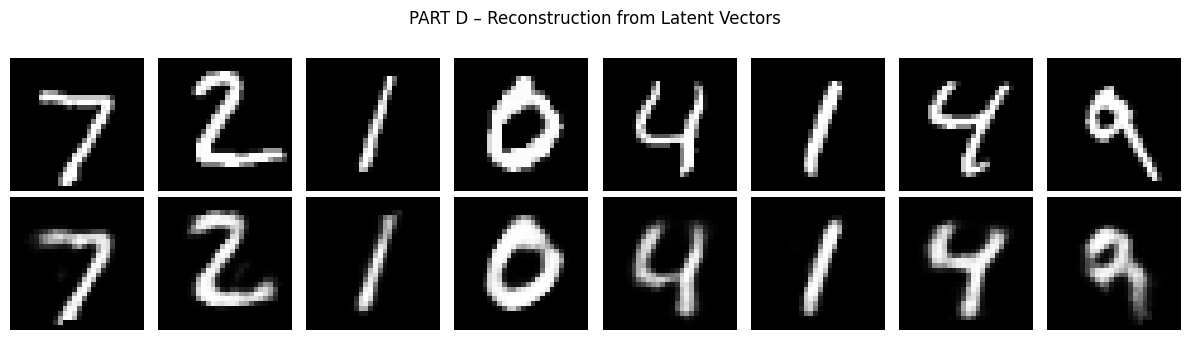

,Metric,Value
0,Original features,784.000000
1,Latent features,32.000000
2,Reduction (%),95.920000
3,Test reconstruction MSE,0.013333


Nitheeswaran M 24BAD079


In [8]:
latent_test = encoder.predict(x_test, batch_size=256, verbose=0)
print("Original test shape:", x_test.shape)
print("Learned latent shape:", latent_test.shape)
print("Features per image: 784 -> 32")
print(f"Dimensionality reduction: {(1 - 32 / 784) * 100:.2f}%")

# PCA is exclusively for a 2D view of the trained Encoder's 32D features.
visualization_count = 2000
latent_2d = PCA(n_components=2, random_state=42).fit_transform(
    latent_test[:visualization_count]
)
plt.figure(figsize=(8, 6))
points = plt.scatter(latent_2d[:, 0], latent_2d[:, 1],
                     c=y_test[:visualization_count], cmap="tab10", s=7, alpha=0.7)
plt.colorbar(points, ticks=range(10), label="Digit label")
plt.xlabel("First principal component of latent features")
plt.ylabel("Second principal component of latent features")
plt.title("PART D – Learned Latent Features (PCA View)")
plt.show()

# Reconstruct selected test samples directly from their latent vectors.
selected = np.array([0, 1, 2, 3, 4, 5, 6, 7])
decoded_selected = decoder.predict(latent_test[selected], verbose=0)
fig, axes = plt.subplots(2, len(selected), figsize=(12, 3.5))
for col, idx in enumerate(selected):
    axes[0, col].imshow(x_test[idx].reshape(28, 28), cmap="gray")
    axes[1, col].imshow(decoded_selected[col].reshape(28, 28), cmap="gray")
    axes[0, col].axis("off")
    axes[1, col].axis("off")
axes[0, 0].set_ylabel("Original")
axes[1, 0].set_ylabel("Decoded")
plt.suptitle("PART D – Reconstruction from Latent Vectors")
plt.tight_layout()
plt.show()

observations = pd.DataFrame({
    "Metric": ["Original features", "Latent features", "Reduction (%)", "Test reconstruction MSE"],
    "Value": [784, 32, round((1 - 32 / 784) * 100, 2), round(float(manual_mse), 6)]
})
display(observations)
print("Nitheeswaran M 24BAD079")

## RESULT
A Dense Autoencoder was implemented for MNIST reconstruction and feature learning.